# Comparison of Data-Driven Uncertainty Quantification Methods for a Carbon Dioxide Storage Benchmark Scenario: Active Subspaces of the Benchmark's CO$_2$ Saturation

**Markus Köppel**¹, **Fabian Franzelin**², **Ilja Kröker**¹, **Sergey Oladyshkin**³, **Gabriele Santin**¹, **Dominik Wittwar**¹, **Andrea Barth**¹, **Bernard Haasdonk**¹, **Wolfgang Nowak**³, **Dirk Pflüger**², **Christian Rohde**¹

¹ IANS, Universität Stuttgart, Pfaffenwaldring 57, 70569 Stuttgart, Germany
² IPVS, Universität Stuttgart, Universitätsstraße 38, 70569 Stuttgart, Germany
³ IWS, Universität Stuttgart, Pfaffenwaldring 5a, 70569 Stuttgart, Germany

M. Köppel et al., "Comparison of data-driven uncertainty quantification methods for a carbon dioxide storage benchmark scenario", *Computational Geosciences* 23(2):339–354, 2019, [doi:10.1007/s10596-018-9785-x](https://doi.org/10.1007/s10596-018-9785-x). Read from the open-access preprint, arXiv:1802.03064v1; page and equation numbers below are the preprint's.

Notebook: Claude (Anthropic) for P. Constantine, 2026

The notebook runs in Python 3 with numpy and matplotlib and the [active_subspaces](https://github.com/paulcon/active_subspaces) library, version 1.0 or later, in about 10 seconds. It reads stored runs of the benchmark's executable and does not run it.

## Summary

The benchmark of Köppel et al. injects CO$_2$ for 100 days into a radially symmetric saline aquifer and asks how three uncertain inputs (the injection rate, the degree of the relative permeability curves and the porosity, given as 10,000 coded samples) affect the CO$_2$ saturation $S(r)$. The data here are outputs of the authors' own finite-volume code, the executable in the benchmark's archive, run on the archive's 10,000 samples: their mean and standard deviation over $r$ reproduce the authors' published Monte Carlo reference to about $10^{-8}$, so these are the runs behind the paper's reference. For the radius of the CO$_2$ plume front, local linear fits give a one-dimensional active subspace with a large gap ($\lambda_1/\lambda_2 = 78$): $\mathbf w_1$ is the porosity (0.997) with a small injection-rate part (0.080), and a polynomial in this one variable has a leave-one-out $R^2$ of 0.978. The saturation at $r = 100.4$ m, where the reference standard deviation peaks, has nearly the same leading direction but jumps as the front passes. This agrees with the paper's statement that the injection rate and the porosity are the main sources of uncertainty and that the relative permeability degree hardly matters (its weight is 0.007), and it adds an ordering: porosity first by far.

## Active subspaces in brief

For a function $f(\mathbf x)$ of $m$ normalized inputs with density $\rho$, the active subspace is spanned by the leading eigenvectors of $\mathbf C = \int \nabla f\, \nabla f^T \rho\, d\mathbf x = \mathbf W \Lambda \mathbf W^T$. A large gap after the $n$-th eigenvalue means that $f$ changes mostly along the $n$ directions $\mathbf W_1$, so $f(\mathbf x) \approx g(\mathbf W_1^T \mathbf x)$, and a scatter plot of $f$ against $\mathbf W_1^T\mathbf x$ (a sufficient summary plot) shows the dependence. When only values are available, $\mathbf C$ can be estimated from gradients of local linear fits, or from a fitted global quadratic. See P. G. Constantine, [*Active Subspaces: Emerging Ideas for Dimension Reduction in Parameter Studies*](https://doi.org/10.1137/1.9781611973860), SIAM, 2015.

## The model

**Equations** (paper Sec. 2, Table 1). CO$_2$ and brine are incompressible and immiscible, capillary pressure is neglected, the aquifer is homogeneous, and the pressure is analytic, so the total radial flux is $Q/r$ with the injection rate $Q = C_p\, q_{CO_2}(1 + \theta_1)$ (Eq. 13). The CO$_2$ saturation $S(r, t)$ obeys a radial Buckley–Leverett conservation law,

$$\phi\,\frac{\partial S}{\partial t} + \frac{1}{r}\,\frac{\partial}{\partial r}\big(Q\, f(S; n)\big) - q_{CO_2} = 0, \qquad f(S;n) = \frac{S^{n}/\mu_g}{S^{n}/\mu_g + (1-S)^{n}/\mu_w},$$

with $S = 0$ initially and $S = 0.8$ at the well, $\mu_g = 3.95\cdot10^{-5}$ Pa s and $\mu_w = 2.535\cdot 10^{-4}$ Pa s. Eq. (11) as printed (p. 4) has a minus sign before the flux term; its semi-discrete form, Eq. (12), and the physics require the plus sign written here. The authors solve it with a semi-discrete central-upwind finite-volume scheme (Kurganov and Petrova) on 250 cells over $0 \le r \le 250$ m with second-order Runge–Kutta time steps, to $t = 100$ days.

**The code.** The benchmark's Zenodo archive holds the authors' solver only as executables (`prog` for Linux, `win_prog.exe` for Windows; no source). `prog` was run for this data set on the archive's 10,000 samples with its defaults (250 cells, 100 days, test case 5023: uncertain injection rate, relative permeability degree and porosity) and wrote $S$ at the 250 cell positions for every sample (`DATA.md`, "Regenerating").

**Inputs** ($m = 3$; Sec. 3, Fig. 1). The archive gives the inputs only as coded samples, `ir` (injection rate $\theta_1$), `kd` (relative permeability degree $\theta_2$) and `po` (porosity $\theta_3$), described as "the distribution of the uncertain parameters"; the maps from the codes to $Q$, $n$ and $\phi$ are inside the executable and are not stated. The paper's Fig. 1 shows $n$ on [2, 4], the porosity on about [0, 0.73] and the injection rate as a skewed distribution; the samples come from data-driven distributions (porosity from a database of reservoir properties) and are independent. This notebook works with the coded inputs as they are.

**Quantities of interest** at $t = 100$ days: the radius of the CO$_2$ plume front, and the saturation $S$ at $r = 100.4$ m, near where the reference standard deviation of $S$ peaks (paper Fig. 2).

In [1]:
%matplotlib inline
import time
import warnings

import numpy as np
import matplotlib.pyplot as plt
import active_subspaces as ac

warnings.formatwarning = lambda msg, cat, *args, **kwargs: f'{cat.__name__}: {msg}\n'
SEED = 933827                        # the only seed (bootstrap replicates)
t_start = time.perf_counter()


def read_csv(path):
    return np.loadtxt(path, delimiter=',', comments='#', ndmin=2)

## Load the data

`benchmark_input_samples.csv` holds the archive's 10,000 coded samples and `mc_reference_mean_std.csv` the authors' Monte Carlo reference curves, both converted losslessly from the archive. `saturation_field.npz` holds $S$ at the 250 cells for every sample, as `prog` printed it; `outputs.csv` repeats five of its columns for readers who want a CSV.

In [2]:
C = read_csv('benchmark_input_samples.csv')        # coded inputs (ir, kd, po), the archive's 10,000 samples
field = np.load('saturation_field.npz')
S, r = field['S'], field['r']                         # S(r, 100 d): 10000 x 250, r: 250 cell positions (m)
F5 = read_csv('outputs.csv')                          # S at r = 50.2, 75.3, 100.4, 125.5, 150.6 m
MC = read_csv('mc_reference_mean_std.csv')            # x, eal, sal, eir, sir, ekd, skd, epo, spo
print('C', C.shape, 'S', S.shape, 'r', r.shape, 'outputs', F5.shape, 'MC reference', MC.shape)
print('outputs.csv equals the field at cells 50, 75, 100, 125, 150:', np.array_equal(F5, S[:, [50, 75, 100, 125, 150]]))
print(f'r: {r[0]:g} to {r[-1]:g} m in steps of {r[1] - r[0]:.6f} m; same grid as the reference: {np.allclose(r, MC[:, 0], atol=1e-6)}')
print(f'S in [{S.min():.3g}, {S.max():.16g}]')
names = ['ir', 'kd', 'po']
labels = ['injection rate (ir)', 'rel. perm. degree (kd)', 'porosity (po)']
for j, nm in enumerate(names):
    q = np.percentile(C[:, j], [0, 5, 50, 95, 100])
    print(f'{nm}: min {q[0]:.4f}, 5% {q[1]:.4f}, median {q[2]:.4f}, 95% {q[3]:.4f}, max {q[4]:.4f}; '
          f'mean {C[:, j].mean():.4f}, sd {C[:, j].std():.4f}')
print('correlations between the coded inputs:', np.array2string(np.corrcoef(C.T)[np.triu_indices(3, 1)], precision=3))

C (10000, 3) S (10000, 250) r (250,) outputs (10000, 5) MC reference (250, 9)
outputs.csv equals the field at cells 50, 75, 100, 125, 150: True
r: 0 to 250 m in steps of 1.004016 m; same grid as the reference: True
S in [0, 0.8000000000000013]
ir: min 0.0471, 5% 0.3378, median 0.6883, 95% 0.9241, max 0.9979; mean 0.6679, sd 0.1799
kd: min 0.0004, 5% 0.0732, median 0.5021, 95% 0.9260, max 0.9996; mean 0.5012, sd 0.2681
po: min -0.4640, 5% -0.2348, median 0.4822, 95% 1.6402, max 3.3976; mean 0.5630, sd 0.5832
correlations between the coded inputs: [-0.009 -0.004  0.007]


### Check: these runs against the authors' Monte Carlo reference

The archive also holds the authors' Monte Carlo mean and standard deviation of $S(r)$ over the 10,000 samples (the paper's reference, Fig. 2). If these runs are the authors' runs, their statistics must reproduce it.

joint case: max |mean - reference| 4.9e-09, max |sd - reference| 5.0e-09 (sd with ddof = 1; with ddof = 0: 1.5e-05)
r = 100.4 m: mean 0.308251 (reference 0.308251), sd 0.309293 (reference 0.309293)
largest sd 0.3095 at r = 98.4 m


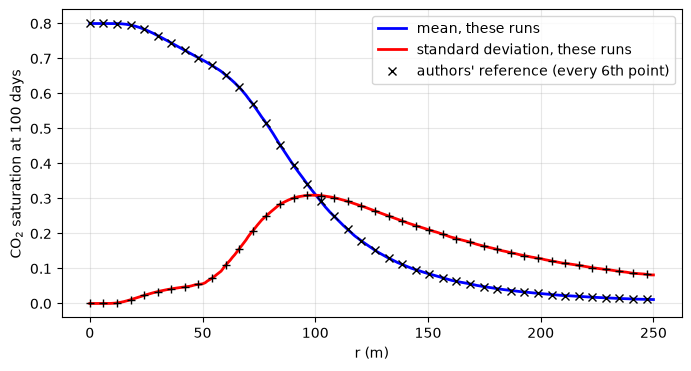

In [3]:
m, sd = S.mean(axis=0), S.std(axis=0, ddof=1)
print(f'joint case: max |mean - reference| {np.abs(m - MC[:, 1]).max():.1e}, max |sd - reference| {np.abs(sd - MC[:, 2]).max():.1e} '
      f'(sd with ddof = 1; with ddof = 0: {np.abs(S.std(axis=0) - MC[:, 2]).max():.1e})')
k100 = 100
print(f'r = {r[k100]:.1f} m: mean {m[k100]:.6f} (reference {MC[k100, 1]:.6f}), sd {sd[k100]:.6f} (reference {MC[k100, 2]:.6f})')
kmax = np.argmax(sd)
print(f'largest sd {sd[kmax]:.4f} at r = {r[kmax]:.1f} m')
fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(r, m, 'b-', lw=2, label='mean, these runs')
ax.plot(r, sd, 'r-', lw=2, label='standard deviation, these runs')
ax.plot(MC[::6, 0], MC[::6, 1], 'kx', label="authors' reference (every 6th point)")
ax.plot(MC[::6, 0], MC[::6, 2], 'k+')
ax.set_xlabel('r (m)'); ax.set_ylabel('CO$_2$ saturation at 100 days'); ax.legend(); ax.grid(True, alpha=0.3)
plt.close(fig)
fig

The mean and the standard deviation (with the $1/(N-1)$ normalization) agree with the reference to $5\cdot10^{-9}$ at every radius, the precision of the archive's file: the paper's reference was computed with this executable on exactly these samples. The two curves are those of the paper's Fig. 2.

### Quantities of interest

The **front radius** is the largest cell position $r$ at which $S > 0.01$. It moves in steps of the cell size, 1.004 m, and it is capped at 250 m for the samples whose plume reaches the end of the domain. Because the code is a shock-capturing scheme, the front is smeared over a few cells, and a threshold of 0.01 marks its leading edge. The **saturation at $r = 100.4$ m** is 0 until the front arrives and then jumps to the shock saturation, so it is a discontinuous function of the inputs.

In [4]:
above = S > 1e-2
front = np.where(above.any(axis=1), r[np.where(above, np.arange(S.shape[1]), -1).max(axis=1)], 0.0)
s100 = S[:, k100]
print(f'front radius: {front.min():.1f} to {front.max():.1f} m, median {np.median(front):.1f} m; '
      f'{(front >= r[-1]).sum()} samples ({(front >= r[-1]).mean():.1%}) reach the end of the domain (250 m)')
print('front radius percentiles 5, 25, 75, 95 %:', np.array2string(np.percentile(front, [5, 25, 75, 95]), precision=1), 'm')
print(f'S at {r[k100]:.1f} m: {(s100 == 0).mean():.1%} of samples exactly 0 (front not yet there), '
      f'{(s100 > 0.7).mean():.1%} above 0.7')
print(f'corr(front, po) = {np.corrcoef(front, C[:, 2])[0, 1]:.3f}, corr(front, ir) = {np.corrcoef(front, C[:, 0])[0, 1]:.3f}, '
      f'corr(front, kd) = {np.corrcoef(front, C[:, 1])[0, 1]:.3f}')

front radius: 45.2 to 250.0 m, median 100.4 m; 190 samples (1.9%) reach the end of the domain (250 m)
front radius percentiles 5, 25, 75, 95 %: [ 66.3  83.3 126.5 196.8] m
S at 100.4 m: 48.4% of samples exactly 0 (front not yet there), 3.9% above 0.7
corr(front, po) = -0.826, corr(front, ir) = 0.221, corr(front, kd) = -0.006


## Estimate the subspace: front radius

**Estimator.** There are no gradients. With 10,000 samples in three dimensions, local linear fits are well determined: `ac.local_linear_gradients` fits a linear model to the 8 nearest samples of each sample and uses its slope as the gradient, and $\hat{\mathbf C}$ is the average of the outer products over the samples, so the density is the empirical distribution of the archive's samples (not uniform; the coded porosity is skewed). The input space `ac.Uniform` on the sample range only scales each code to $[-1, 1]$. The bootstrap uses 200 replicates of the gradients with `rng=SEED`. As checks, the global quadratic (QPHD [5]) and the linear least-squares (OLS) directions are computed too; the library warns that both rest on assumptions about the input density that do not hold here, so they are compared only for the direction. $\mathbf w_1$ is oriented to correlate positively with the front radius.

local-linear gradients (p = 8): 4.8 s; n = 1 by the gap rule
eigenvalues: [59009.6508   757.1024   477.5611] ; l1/l2 = 77.9, l2/l3 = 1.59
95% bootstrap intervals: [5.676e+04, 6.161e+04]; [641.6, 852.7]; [399.2, 542.8]
bootstrap mean subspace distance, k = 1, 2: [0.003  0.0829]
w1 (local linear): [ 0.0795 -0.0073 -0.9968]  w2: [ 0.9629 -0.2581  0.0787]
QPHD: l1/l2 = 130, w1 = [ 0.0792  0.0024 -0.9969] |w1(QPHD) . w1| = 1.0000; |w1(OLS) . w1| = 0.9918


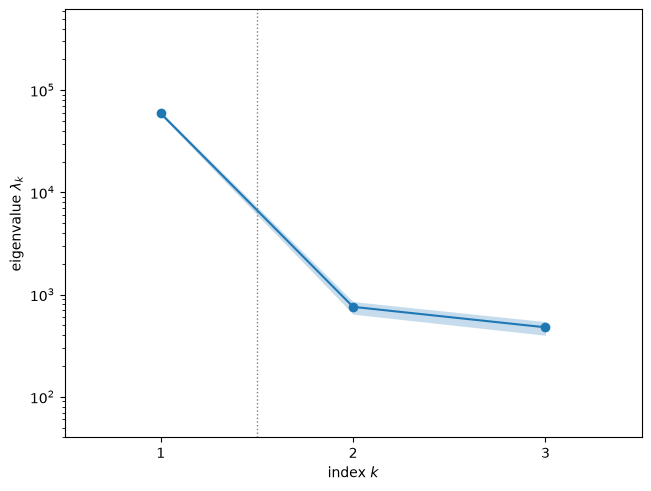

In [5]:
space = ac.Uniform(C.min(axis=0), C.max(axis=0), names=names)
Xn = space.to_normalized(C)
t0 = time.perf_counter()
G = ac.local_linear_gradients(X=C, f=front, space=space, p=8)
sub = ac.active_subspace(space=space, grads=G, nboot=200, rng=SEED)
sub = ac.orient(sub, by='covariance', X=C, f=front, columns=2)
q = ac.active_subspace(space=space, X=C, f=front, estimator='qphd', nboot=200, rng=SEED)
q = ac.orient(q, by='covariance', X=C, f=front, columns=1)
ols = ac.active_subspace(space=space, X=C, f=front, estimator='ols')
lam = sub.eigenvalues
print(f'local-linear gradients (p = 8): {time.perf_counter() - t0:.1f} s; n = {sub.n} by the gap rule')
print('eigenvalues:', np.array2string(lam, precision=4), f'; l1/l2 = {lam[0] / lam[1]:.1f}, l2/l3 = {lam[1] / lam[2]:.2f}')
lo, hi = np.percentile(sub.bootstrap_eigenvalues, [2.5, 97.5], axis=0)
print('95% bootstrap intervals:', '; '.join(f'[{a:.4g}, {b:.4g}]' for a, b in zip(lo, hi)))
print('bootstrap mean subspace distance, k = 1, 2:', np.array2string(sub.bootstrap_distances.mean(axis=0)[:2], precision=4))
print('w1 (local linear):', np.array2string(sub.W[:, 0], precision=4), ' w2:', np.array2string(sub.W[:, 1], precision=4))
print(f'QPHD: l1/l2 = {q.eigenvalues[0] / q.eigenvalues[1]:.0f}, w1 =', np.array2string(q.W[:, 0], precision=4),
      f'|w1(QPHD) . w1| = {abs(q.W[:, 0] @ sub.W[:, 0]):.4f}; |w1(OLS) . w1| = {abs(ols.W[:, 0] @ sub.W[:, 0]):.4f}')
fig, ax = ac.plotting.plot_eigenvalues(sub)
plt.close(fig)
fig

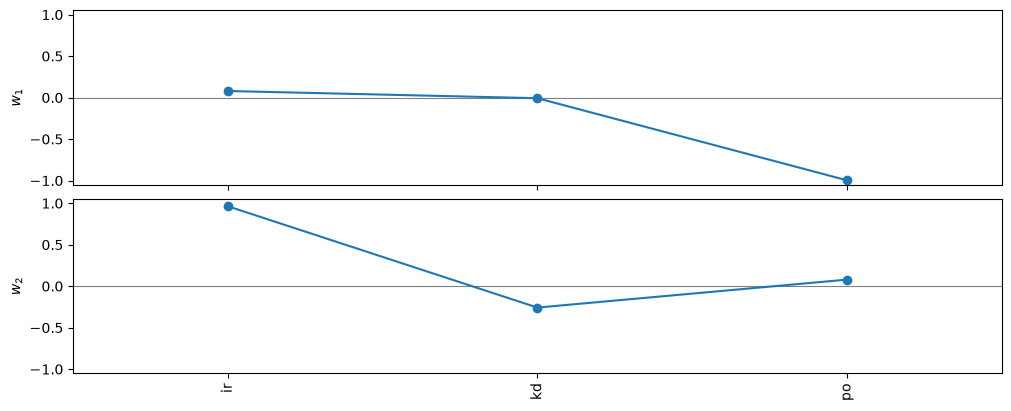

In [6]:
fig, axes = ac.plotting.plot_eigenvectors(sub, indices=[0, 1], labels=names, figsize=(10, 4))
plt.close(fig)
fig

**Dimension.** The first eigenvalue is 78 times the second (bootstrap intervals [56,760, 61,610] and [642, 853] are far apart), while the second and third differ by a factor 1.6, and the bootstrap mean distance between the one-dimensional subspace and its replicates is 0.003: we choose $n = 1$. QPHD gives the same direction ($|\mathbf w_1^T\mathbf w_{1,\rm QPHD}| = 1.0000$, with an even larger ratio, 130) and OLS nearly the same (0.992).

**Eigenvectors.** $\mathbf w_1 = (0.080, -0.007, -0.997)$ in (`ir`, `kd`, `po`): the front is set almost entirely by the porosity, which fills the pore space the injected CO$_2$ must displace, with a small push from the injection rate; $\mathbf y_1$ grows as the porosity falls and the rate rises. The relative permeability degree has weight 0.007. $\mathbf w_2$ is mostly the injection rate (0.963) with some of the degree (−0.258), but its eigenvalue is 1.3 % of the first.

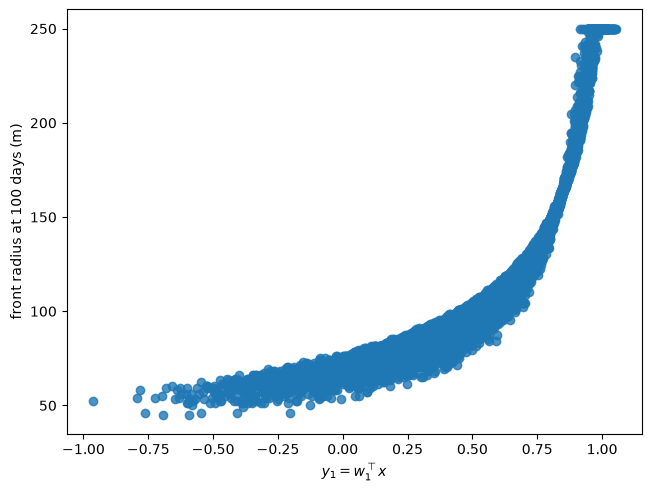

In [7]:
fig, ax = ac.plotting.plot_sufficient_summary(sub, X=C, f=front, dims=1, qoi_label='front radius at 100 days (m)')
plt.close(fig)
fig

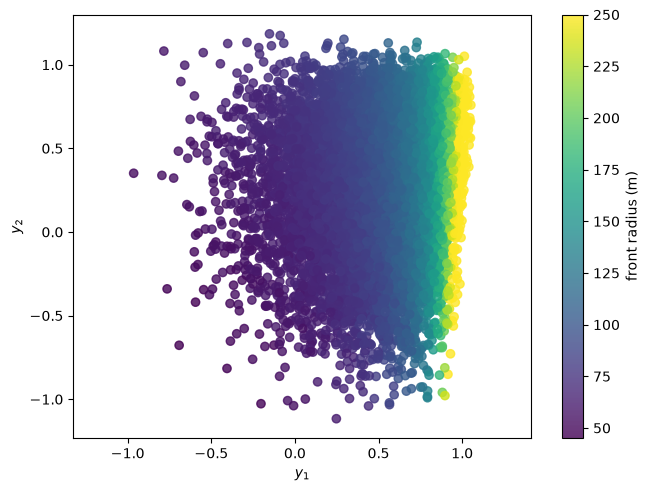

In [8]:
fig, ax = ac.plotting.plot_sufficient_summary(sub, X=C, f=front, dims=2, qoi_label='front radius (m)')
plt.close(fig)
fig

In [9]:
sur = {}
for k, deg in [(1, 3), (1, 5), (2, 3)]:
    sur[(k, deg)] = ac.fit_surrogate(X=C, f=front, space=space, subspace=ac.with_dimension(sub, k), kind='poly', degree=deg)
    print(f'polynomial of degree {deg} in {k} active variable(s): LOO R^2 = {sur[(k, deg)].loo_r_squared:.5f}')
y1 = Xn @ sub.W[:, 0]
print(f'corr(front, y1) = {np.corrcoef(front, y1)[0, 1]:.4f}')

polynomial of degree 3 in 1 active variable(s): LOO R^2 = 0.95761
polynomial of degree 5 in 1 active variable(s): LOO R^2 = 0.97842
polynomial of degree 3 in 2 active variable(s): LOO R^2 = 0.96714
corr(front, y1) = 0.8436


The one-dimensional summary plot is a single thin, monotone curve: half the fronts lie between 83 and 127 m (5–95 %: 66–197 m), and the curve rises steeply at the high end of $y_1$ (the lowest porosity codes), up to the 250 m cap for 190 samples (1.9 %). The colour in the two-dimensional plot changes almost only along $y_1$; the thin spread about the curve is ordered by the injection rate. A cubic in $y_1$ has leave-one-out $R^2$ 0.958 and a quintic 0.978 (the steep rise is hard for low-degree polynomials); a cubic in $(y_1, y_2)$ gives 0.967. One active variable describes the front radius.

S(100.4 m): n = 1; eigenvalues [5.6117 0.8298 0.7411] ; l1/l2 = 6.8
w1: [ 0.2439  0.0064 -0.9698] ; |w1(S100) . w1(front)| = 0.9860
bootstrap mean subspace distance, k = 1: 0.0190


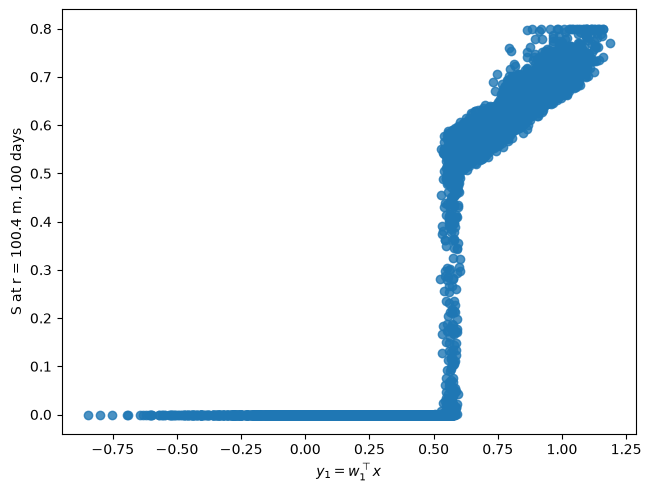

In [10]:
G100 = ac.local_linear_gradients(X=C, f=s100, space=space, p=8)
s1 = ac.active_subspace(space=space, grads=G100, nboot=200, rng=SEED)
s1 = ac.orient(s1, by='covariance', X=C, f=s100, columns=1)
l1 = s1.eigenvalues
print(f'S(100.4 m): n = {s1.n}; eigenvalues', np.array2string(l1, precision=4), f'; l1/l2 = {l1[0] / l1[1]:.1f}')
print('w1:', np.array2string(s1.W[:, 0], precision=4), f'; |w1(S100) . w1(front)| = {abs(s1.W[:, 0] @ sub.W[:, 0]):.4f}')
print('bootstrap mean subspace distance, k = 1:', f'{s1.bootstrap_distances.mean(axis=0)[0]:.4f}')
fig, ax = ac.plotting.plot_sufficient_summary(s1, X=C, f=s100, dims=1, qoi_label='S at r = 100.4 m, 100 days')
plt.close(fig)
fig

## The saturation at $r = 100.4$ m

The same estimator for $S$ at 100.4 m (above) gives one leading direction, $\mathbf w_1 = (0.244, 0.006, -0.970)$, within $|\cos| = 0.986$ of the front's, with a smaller gap ($\lambda_1/\lambda_2 = 6.8$; bootstrap distance 0.019). The summary plot shows why: $S$ is 0 for the 48 % of samples whose front has not reached 100.4 m, jumps to about 0.5–0.6 when it passes, near $y_1 \approx 0.5$, and then rises along the rarefaction towards the well value 0.8. The jump is spread over a band of $y_1$ that the injection rate orders, so the rate has a larger weight here than for the front radius. Local linear fits across a jump are not gradients, and the eigenvalues of a discontinuous function depend on the fit radius, so only the direction should be read: the porosity leads, the injection rate is second and the relative permeability degree does not matter.

## Comparison with the paper

The paper does no active-subspace analysis; it compares four surrogate methods against the Monte Carlo reference, and says (p. 5) that the relative permeability degree "does not influence the saturation significantly" and that the injection rate and the porosity are the main sources of uncertainty. The table is printed from the results above.

In [11]:
w = sub.W[:, 0]
rows = [
    ('mean and sd of S(r) over the 10,000 runs (joint)', "Fig. 2; MCrefs_MeanStd.csv",
     f'equal to {max(np.abs(m - MC[:, 1]).max(), np.abs(sd - MC[:, 2]).max()):.0e}'),
    ('main sources of uncertainty (p. 5)', 'injection rate and porosity', f'|w1|: po {abs(w[2]):.3f}, ir {abs(w[0]):.3f}'),
    ('relative permeability degree (p. 5)', 'does not influence S significantly', f'|w1| {abs(w[1]):.4f}'),
    ('active subspace of the front radius', 'not reported', f'n = {sub.n}, l1/l2 = {lam[0] / lam[1]:.0f}'),
]
print(f'{"quantity":50s} | {"paper":36s} | notebook')
for a, b, c in rows:
    print(f'{a:50s} | {b:36s} | {c}')
print(f'\nnotebook run time: {time.perf_counter() - t_start:.0f} s')

quantity                                           | paper                                | notebook
mean and sd of S(r) over the 10,000 runs (joint)   | Fig. 2; MCrefs_MeanStd.csv           | equal to 5e-09
main sources of uncertainty (p. 5)                 | injection rate and porosity          | |w1|: po 0.997, ir 0.080
relative permeability degree (p. 5)                | does not influence S significantly   | |w1| 0.0073
active subspace of the front radius                | not reported                         | n = 1, l1/l2 = 78

notebook run time: 10 s


## References

1. M. Köppel, F. Franzelin, I. Kröker, S. Oladyshkin, G. Santin, D. Wittwar, A. Barth, B. Haasdonk, W. Nowak, D. Pflüger, C. Rohde. Comparison of data-driven uncertainty quantification methods for a carbon dioxide storage benchmark scenario. *Computational Geosciences* 23(2):339–354, 2019. [doi:10.1007/s10596-018-9785-x](https://doi.org/10.1007/s10596-018-9785-x)
2. M. Köppel et al. Datasets and executables of data-driven uncertainty quantification benchmark in carbon dioxide storage. Zenodo, 2017. [doi:10.5281/zenodo.933827](https://doi.org/10.5281/zenodo.933827)
3. H. Class et al. A benchmark study on problems related to CO2 storage in geologic formations. *Computational Geosciences* 13(4):409–434, 2009. [doi:10.1007/s10596-009-9146-x](https://doi.org/10.1007/s10596-009-9146-x)
4. A. Kurganov, G. Petrova. Central-upwind schemes on triangular grids for hyperbolic systems of conservation laws. *Numerical Methods for Partial Differential Equations* 21(3):536–552, 2005. [doi:10.1002/num.20049](https://doi.org/10.1002/num.20049)
5. K.-C. Li. On principal Hessian directions for data visualization and dimension reduction: another application of Stein's lemma. *Journal of the American Statistical Association* 87(420):1025–1039, 1992. [doi:10.1080/01621459.1992.10476258](https://doi.org/10.1080/01621459.1992.10476258)
6. P. G. Constantine. *Active Subspaces: Emerging Ideas for Dimension Reduction in Parameter Studies.* SIAM, 2015. [doi:10.1137/1.9781611973860](https://doi.org/10.1137/1.9781611973860)

## Acknowledgments

The paper's authors thank the German Research Foundation (DFG) for financial support within the Cluster of Excellence in Simulation Technology (EXC 310/2) at the University of Stuttgart.